<a href="https://colab.research.google.com/github/omarelmalak/csc490-group2/blob/main/Sponsor_Inference_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎬 Sponsor Logo Inference Pipeline (detector + doctor)

**纯推理** notebook：不训练，只加载已训好的权重，对一段转播视频跑完整链路并输出品牌曝光时长。

```
video frame
  ├─ Player Detector (YOLOv8)      -> 人体框
  ├─ Logo Detector (YOLOv8, 单类)  -> logo 候选
  │     └─ + 几何先验（胸口/袖口/短裤）
  ├─ 软匹配 logo↔player（外扩 10% + 面积 0.55 + 中心点兜底）
  ├─ Doctor (ResNet-50) 批量分类 + hflip TTA + 温度标定
  └─ ByteTrack 跟踪 → 每个 track 概率投票 → 曝光时长 CSV
```

测试视频：`https://www.youtube.com/watch?v=yxM140uJEZI`

## 使用步骤

1. 跑 `0. 环境依赖`
2. `1. 配置` 里确认权重路径（跑完 v3 训练 notebook 后一般在 `/content/runs` 和 `/content/artifacts`）
3. 依次往下跑

不想跑全片就把 `MAX_SECONDS` 设成 120 先看效果。

## 0. 环境依赖

In [1]:
INSTALL_DEPS = True

if INSTALL_DEPS:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "ultralytics", "yt-dlp", "pyyaml", "pandas", "tqdm"])

## 1. 导入 & 全局配置

In [2]:
import re
import subprocess
import time
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.transforms as T
from PIL import Image
from torchvision.models import resnet50
from ultralytics import YOLO

try:
    from IPython.display import display
except Exception:
    display = print

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = torch.cuda.is_available()
print("torch:", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
torch: 2.14.1+cu130 | CUDA: True | Tesla T4


In [3]:
# ============================== 权重位置 ==============================
# 训练 notebook 的产物默认在 /content 下；如果你存在 Drive，把 ROOT 换成挂载路径
ROOT = Path("/content")

PLAYER_WEIGHTS = ROOT /"player.pt"
LOGO_WEIGHTS = ROOT /"logo.pt"
DOCTOR_WEIGHTS = ROOT /"resnet50_doctor_v2.pth"

# 找不到时的备选搜索路径（会把 ROOT 下所有同名权重都扫一遍）
SEARCH_FALLBACK = True

# ============================== 视频 ==============================
VIDEO_URL = "https://www.youtube.com/watch?v=yxM140uJEZI"
LOCAL_VIDEO = None            # 已经有本地文件就直接填路径，跳过下载
DOWNLOAD_DIR = ROOT / "videos"
VIDEO_MAX_HEIGHT = 720        # 下载分辨率上限
DOWNLOAD_SECTION = None       # 只要片段就填 (起, 止) 秒，例如 (60, 240)
MAX_SECONDS = 120             # 只处理前 N 秒（None = 全片，会很慢）
FRAME_STRIDE = 1              # 每 N 帧取 1 帧
PROC_MAX_WIDTH = 1280         # 推理前把画面缩到这个宽度，省显存提速度

# ============================== 模型推理参数 ==============================
IMGSZ = 1280
PLAYER_CONF = 0.25
LOGO_CONF = 0.10
LOGO_IOU = 0.50
LOGO_MAX_DET = 300

# 软匹配
CONTAINMENT_PAD = 0.10
CONTAINMENT_AREA_THR = 0.55
REQUIRE_PLAYER_CONTAINMENT = True

# Doctor
DOCTOR_INPUT = 224
CROP_CONTEXT = 0.15           # crop 外扩，保留球衣纹理
DOCTOR_USE_TTA = True
DOCTOR_MIN_CONF = 0.45
DOCTOR_MIN_MARGIN = 0.15

# 几何先验（赞助商位置先验，提升"没见过的 logo"召回）
USE_GEOMETRIC_PRIORS = True
PRIOR_CONF = 0.35
PRIOR_MIN_CONF = 0.60
PRIOR_MIN_MARGIN = 0.25
FUSED_NMS_IOU = 0.55
MAX_ACCEPTED_PER_PLAYER = 2

# 跟踪 / 输出
TRACKER_CFG = "bytetrack.yaml"
MIN_TRACK_FRAMES = 3          # 少于这么多帧的 track 直接丢掉（抗抖）
OUT_DIR = ROOT / "inference_out"
SAVE_ANNOTATED_VIDEO = False
SAVE_BRAND_CROPS = True
CROP_SAVE_LIMIT = 30          # 每个品牌最多存多少张代表图

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("OUT_DIR =", OUT_DIR)

OUT_DIR = /content/inference_out


## 2. 检查权重（找不到会告诉你怎么办）

如果三个权重不在 `/content` 下，最常见的两种情况：
- 换了 Colab 会话 → 之前的文件已经没了，需要挂载 Drive 或重跑训练；
- 只训练了一部分 → 至少 Player + Logo + Doctor 三个都要有，缺一个跑不了。

In [4]:
def _find_weight(path, name):
    path = Path(path)
    if path.exists():
        return path
    if SEARCH_FALLBACK:
        hits = sorted(ROOT.rglob(name))
        hits = [h for h in hits if h.is_file() and h.stat().st_size > 1024]
        if hits:
            print("[fallback] %s -> %s" % (name, hits[0]))
            return hits[0]
    return None


PLAYER_WEIGHTS = _find_weight(PLAYER_WEIGHTS, "best.pt")
_logo = _find_weight(LOGO_WEIGHTS, "best.pt")
if _logo is not None and PLAYER_WEIGHTS is not None and _logo == PLAYER_WEIGHTS:
    _logo = None
LOGO_WEIGHTS = _logo
DOCTOR_WEIGHTS = _find_weight(DOCTOR_WEIGHTS, "resnet50_doctor_v2.pth")

_missing = [n for n, p in (("PLAYER_WEIGHTS", PLAYER_WEIGHTS),
                           ("LOGO_WEIGHTS", LOGO_WEIGHTS),
                           ("DOCTOR_WEIGHTS", DOCTOR_WEIGHTS)) if p is None]
assert not _missing, (
    "缺少权重: %s\n"
    "  1) 如果权重在 Drive: from google.colab import drive; drive.mount('/content/drive') "
    "然后把本格上方 ROOT 改成 /content/drive/MyDrive/你的目录\n"
    "  2) 如果没有: 先跑训练 notebook（Untitled10_v3）" % _missing)

print("PLAYER_WEIGHTS:", PLAYER_WEIGHTS)
print("LOGO_WEIGHTS  :", LOGO_WEIGHTS)
print("DOCTOR_WEIGHTS:", DOCTOR_WEIGHTS)

PLAYER_WEIGHTS: /content/player.pt
LOGO_WEIGHTS  : /content/logo.pt
DOCTOR_WEIGHTS: /content/resnet50_doctor_v2.pth


## 3. 下载测试视频

`yt-dlp` 下载 YouTube。如果遇到 bot 校验，两个办法：
- 换 `VIDEO_URL` 为另一个可下载的片段；
- 自己把视频传到 Colab（或 Drive），把 `LOCAL_VIDEO` 设成文件路径。

In [5]:
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)


def _yt_dlp_cmd(url, out_tmpl, fmt, section=None):
    cmd = ["yt-dlp", "--no-playlist", "-f", fmt,
           "--merge-output-format", "mp4", "-o", out_tmpl, url]
    if section:
        cmd += ["--download-sections", "*%d-%d" % (int(section[0]), int(section[1])),
                "--force-keyframes-at-cuts"]
    return cmd


def download_video(url, out_dir, max_height=720, section=None):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    tmpl = str(out_dir / "%(id)s.%(ext)s")
    formats = [
        "bv*[height<=%d]+ba/b[height<=%d]" % (max_height, max_height),
        "b[height<=%d]/b" % max_height,
    ]
    for fmt in formats:
        cmd = _yt_dlp_cmd(url, tmpl, fmt, section)
        print("$", " ".join(cmd))
        try:
            r = subprocess.run(cmd, capture_output=True, text=True, timeout=1800)
        except Exception as e:
            print("  调用失败:", e)
            continue
        if r.returncode == 0:
            cands = sorted(out_dir.glob("*.mp4")) + sorted(out_dir.glob("*.mkv")) \
                    + sorted(out_dir.glob("*.webm"))
            if cands:
                return max(cands, key=lambda p: p.stat().st_mtime)
        print("  失败:", (r.stderr or "")[-400:])
    raise RuntimeError("yt-dlp 下载失败，请换 URL 或改用 LOCAL_VIDEO")


if LOCAL_VIDEO:
    VIDEO_PATH = Path(LOCAL_VIDEO)
    assert VIDEO_PATH.exists(), VIDEO_PATH
else:
    VIDEO_PATH = download_video(VIDEO_URL, DOWNLOAD_DIR,
                                max_height=VIDEO_MAX_HEIGHT,
                                section=DOWNLOAD_SECTION)

cap_probe = cv2.VideoCapture(str(VIDEO_PATH))
FPS = cap_probe.get(cv2.CAP_PROP_FPS) or 25.0
N_FRAMES = int(cap_probe.get(cv2.CAP_PROP_FRAME_COUNT))
W0 = int(cap_probe.get(cv2.CAP_PROP_FRAME_WIDTH))
H0 = int(cap_probe.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap_probe.release()
print("VIDEO_PATH:", VIDEO_PATH)
print("分辨率: %dx%d | fps=%.2f | 帧数=%d | 时长=%.1f 分钟"
      % (W0, H0, FPS, N_FRAMES, N_FRAMES / max(FPS, 1e-6) / 60))

$ yt-dlp --no-playlist -f bv*[height<=720]+ba/b[height<=720] --merge-output-format mp4 -o /content/videos/%(id)s.%(ext)s https://www.youtube.com/watch?v=yxM140uJEZI
VIDEO_PATH: /content/videos/yxM140uJEZI.mp4
分辨率: 1280x720 | fps=25.00 | 帧数=165472 | 时长=110.3 分钟


## 4. 加载模型

In [6]:
player_detector = YOLO(str(PLAYER_WEIGHTS))
logo_detector = YOLO(str(LOGO_WEIGHTS))

PLAYER_HINTS = {"joueur", "gardien", "player", "goalkeeper", "keeper", "person"}
PLAYER_CLASS_IDS = [i for i, n in player_detector.names.items()
                    if str(n).strip().lower() in PLAYER_HINTS] or None
print("player classes:", player_detector.names, "| 使用:", PLAYER_CLASS_IDS)

try:
    ckpt = torch.load(str(DOCTOR_WEIGHTS), map_location="cpu", weights_only=False)
except TypeError:
    ckpt = torch.load(str(DOCTOR_WEIGHTS), map_location="cpu")

idx_to_class = {int(k): v for k, v in ckpt["idx_to_class"].items()}
TEMPERATURE = float(ckpt.get("temperature", 1.0))
_other_key = ckpt.get("other_key")
OTHER_IDX = None
if _other_key and _other_key in ckpt.get("class_to_idx", {}):
    OTHER_IDX = int(ckpt["class_to_idx"][_other_key])
if OTHER_IDX is None:
    OTHER_IDX = next((i for i, n in idx_to_class.items()
                      if re.sub(r"[^a-z0-9]", "", str(n).lower()) == "other"), None)

model_doctor = resnet50()
model_doctor.fc = nn.Linear(model_doctor.fc.in_features, len(idx_to_class))
model_doctor.load_state_dict(ckpt["model_state"])
model_doctor = model_doctor.to(DEVICE).eval()

print("doctor: %d 类 | T=%.3f | other_idx=%s" % (len(idx_to_class), TEMPERATURE, OTHER_IDX))
print("doctor 前 10 个类别:", [idx_to_class[i] for i in sorted(idx_to_class)][:10])

player classes: {0: 'Arbitre', 1: 'Ballon', 2: 'Gardien', 3: 'Joueur'} | 使用: [2, 3]
doctor: 4903 类 | T=0.707 | other_idx=4902
doctor 前 10 个类别: ['100anos', '100GrandBar', '10 Cane', '1519 Tequila', '1800Tequila', '241 Pizza', '24seven', '2xist', '2XU', '3D-GOLD']


## 5. 工具函数（几何 / 匹配 / 预处理）

Doctor 训练时用的是「保持长宽比 + pad 成正方形」，推理必须一致，否则分布对不上。

In [7]:
def poly_to_xyxy(poly, w, h):
    x1, y1 = poly.min(axis=0)
    x2, y2 = poly.max(axis=0)
    return (max(0, int(np.floor(x1))), max(0, int(np.floor(y1))),
            min(w, int(np.ceil(x2))), min(h, int(np.ceil(y2))))


def containment_ratio(inner_poly, outer_poly):
    inner = np.asarray(inner_poly, np.float32).reshape(-1, 2)
    outer = np.asarray(outer_poly, np.float32).reshape(-1, 2)
    area = abs(cv2.contourArea(inner))
    if area <= 1e-6:
        return 0.0
    inter, _ = cv2.intersectConvexConvex(inner, outer)
    return float(min(1.0, max(0.0, inter / area)))


def expand_poly(poly, pad=0.10):
    x1, y1 = poly.min(axis=0)
    x2, y2 = poly.max(axis=0)
    w, h = max(x2 - x1, 1e-6), max(y2 - y1, 1e-6)
    return np.array([[x1 - pad * w, y1 - pad * h],
                     [x2 + pad * w, y1 - pad * h],
                     [x2 + pad * w, y2 + pad * h],
                     [x1 - pad * w, y2 + pad * h]], dtype=np.float32)


def logo_player_match(logo_poly, player_polys,
                      pad=CONTAINMENT_PAD, area_thr=CONTAINMENT_AREA_THR):
    best, center_in = 0.0, False
    c = logo_poly.mean(axis=0)
    for p in player_polys:
        pe = expand_poly(p, pad)
        best = max(best, containment_ratio(logo_poly, pe))
        x1, y1 = pe.min(axis=0)
        x2, y2 = pe.max(axis=0)
        if x1 <= c[0] <= x2 and y1 <= c[1] <= y2:
            center_in = True
    return (best >= area_thr) or (center_in and best >= 0.30), best, center_in


def result_polygons(result):
    obb = getattr(result, "obb", None)
    if obb is not None and len(obb) > 0:
        return [p.astype(np.float32) for p in
                obb.xyxyxyxy.cpu().numpy().reshape(-1, 4, 2)], obb.conf.cpu().numpy()
    boxes = getattr(result, "boxes", None)
    if boxes is not None and len(boxes) > 0:
        polys, confs = [], []
        for b, c in zip(boxes.xyxy.cpu().numpy(), boxes.conf.cpu().numpy()):
            x1, y1, x2, y2 = b
            polys.append(np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], np.float32))
            confs.append(float(c))
        return polys, np.asarray(confs, np.float32)
    return [], np.asarray([], np.float32)


def iou_xyxy(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    aa = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    bb = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    return inter / (aa + bb - inter + 1e-9)


def geometric_prior_polys(player_polys):
    out = []
    for p in player_polys:
        x1, y1 = p.min(axis=0)
        x2, y2 = p.max(axis=0)
        w, h = max(x2 - x1, 1e-6), max(y2 - y1, 1e-6)

        def rect(fx1, fy1, fx2, fy2):
            return np.array([[x1 + fx1 * w, y1 + fy1 * h],
                             [x1 + fx2 * w, y1 + fy1 * h],
                             [x1 + fx2 * w, y1 + fy2 * h],
                             [x1 + fx1 * w, y1 + fy2 * h]], np.float32)

        out.append(rect(0.22, 0.12, 0.78, 0.42))   # 胸口
        out.append(rect(0.00, 0.10, 0.28, 0.38))   # 左袖
        out.append(rect(0.72, 0.10, 1.00, 0.38))   # 右袖
        out.append(rect(0.25, 0.52, 0.75, 0.85))   # 短裤
    return out


def _poly_aabb_iou(a, b):
    ax1, ay1 = a.min(axis=0); ax2, ay2 = a.max(axis=0)
    bx1, by1 = b.min(axis=0); bx2, by2 = b.max(axis=0)
    return iou_xyxy((ax1, ay1, ax2, ay2), (bx1, by1, bx2, by2))


def nms_proposals(items, iou_thr=FUSED_NMS_IOU):
    keep = []
    for poly, score, src in sorted(items, key=lambda t: -t[1]):
        if all(_poly_aabb_iou(poly, k[0]) < iou_thr for k in keep):
            keep.append((poly, score, src))
    return keep


def poly_with_context(poly, w, h, ctx=CROP_CONTEXT):
    x1, y1 = poly.min(axis=0)
    x2, y2 = poly.max(axis=0)
    dx, dy = (x2 - x1) * ctx, (y2 - y1) * ctx
    return (max(0, int(np.floor(x1 - dx))), max(0, int(np.floor(y1 - dy))),
            min(w, int(np.ceil(x2 + dx))), min(h, int(np.ceil(y2 + dy))))


class KeepAspectPad:
    """训练时用的同款预处理：保持长宽比缩放 + pad 成正方形。"""

    def __init__(self, size=224, fill=114, min_side=32):
        self.size, self.fill, self.min_side = size, fill, min_side

    def __call__(self, img):
        w, h = img.size
        if min(w, h) < self.min_side and w > 0 and h > 0:
            s = self.min_side / min(w, h)
            img = img.resize((max(1, int(w * s)), max(1, int(h * s))), Image.LANCZOS)
            w, h = img.size
        side = max(w, h)
        canvas = Image.new("RGB", (side, side), (self.fill,) * 3)
        canvas.paste(img, ((side - w) // 2, (side - h) // 2))
        return canvas.resize((self.size, self.size), Image.BILINEAR)


val_tf = T.Compose([
    KeepAspectPad(DOCTOR_INPUT),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

print("geometry / preprocess ready.")

geometry / preprocess ready.


## 6. Doctor 批量分类（一次 forward 处理整帧所有候选）

整帧可能有 10~40 个候选（几何先验占大头），逐张前向会慢十倍，所以这里做批处理 + hflip TTA。

In [8]:
from contextlib import nullcontext


def _amp_ctx():
    if not USE_AMP:
        return nullcontext()
    try:
        return torch.amp.autocast("cuda", enabled=True)
    except Exception:
        return torch.cuda.amp.autocast()


@torch.no_grad()
def doctor_predict_batch(image_rgb, polys, tta=DOCTOR_USE_TTA, batch_size=64):
    h, w = image_rgb.shape[:2]
    crops, keep_idx = [], []
    for i, poly in enumerate(polys):
        x1, y1, x2, y2 = poly_with_context(poly, w, h)
        if x2 - x1 < 4 or y2 - y1 < 4:
            continue
        crops.append(image_rgb[y1:y2, x1:x2])
        keep_idx.append(i)
    if not crops:
        return [None] * len(polys)

    results = [None] * len(polys)
    for s in range(0, len(crops), batch_size):
        chunk = crops[s:s + batch_size]
        tensors = []
        for c in chunk:
            img = Image.fromarray(c)
            tensors.append(val_tf(img))
            if tta:
                tensors.append(val_tf(img.transpose(Image.FLIP_LEFT_RIGHT)))
        x = torch.stack(tensors).to(DEVICE)
        with _amp_ctx():
            logits = model_doctor(x)
        probs = (torch.softmax(logits.float() / TEMPERATURE, dim=1)
                 .reshape(len(chunk), -1, logits.size(1)).mean(dim=1))
        top = torch.topk(probs, k=min(5, probs.size(1)), dim=1)
        for r in range(len(chunk)):
            i1 = int(top.indices[r, 0])
            c1 = float(top.values[r, 0])
            margin = float(top.values[r, 0] - top.values[r, 1]) if top.values.size(1) > 1 else 1.0
            is_other = OTHER_IDX is not None and i1 == OTHER_IDX
            results[keep_idx[s + r]] = {
                "brand": idx_to_class[i1],
                "conf": c1,
                "margin": margin,
                "is_unknown": bool(is_other or c1 < DOCTOR_MIN_CONF or margin < DOCTOR_MIN_MARGIN),
                "top5": [(idx_to_class[int(i)], float(v))
                         for i, v in zip(top.indices[r], top.values[r])],
                "crop": chunk[r],
            }
    return results


print("doctor_predict_batch ready.")

doctor_predict_batch ready.


## 7. 单帧分析：proposal 融合 → 分类

一个候选被"接受"需要同时满足：

1. 几何上落在球员身上（软匹配）；
2. Doctor 置信度 / top1-top2 margin 达标；
3. 如果是**几何先验**候选（没有检测证据），门槛更严（`PRIOR_MIN_CONF`）；
4. 同一个球员最多保留 `MAX_ACCEPTED_PER_PLAYER` 个（压误报）。

In [9]:
def analyze_frame(frame_bgr, track_ids=True, persist=True):
    """返回该帧所有被接受的品牌候选记录。"""
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]

    player_res = player_detector(frame_bgr, classes=PLAYER_CLASS_IDS, conf=PLAYER_CONF,
                                 imgsz=IMGSZ, verbose=False, device=DEVICE)[0]

    if track_ids:
        logo_res = logo_detector.track(frame_bgr, conf=LOGO_CONF,
                                       iou=LOGO_IOU, max_det=LOGO_MAX_DET, imgsz=IMGSZ,
                                       agnostic_nms=True, tracker=TRACKER_CFG,
                                       persist=persist,
                                       verbose=False, device=DEVICE)[0]
    else:
        logo_res = logo_detector(frame_bgr, conf=LOGO_CONF, iou=LOGO_IOU,
                                 max_det=LOGO_MAX_DET, imgsz=IMGSZ, agnostic_nms=True,
                                 verbose=False, device=DEVICE)[0]

    player_polys, _ = result_polygons(player_res)
    logo_polys, logo_confs = result_polygons(logo_res)

    tids = None
    if getattr(logo_res, "boxes", None) is not None and logo_res.boxes.id is not None:
        tids = logo_res.boxes.id.int().cpu().tolist()

    props = []
    for poly, conf in zip(logo_polys, logo_confs):
        ok, contain, _ = logo_player_match(poly, player_polys)
        if REQUIRE_PLAYER_CONTAINMENT and not ok:
            continue
        props.append((poly, float(conf), "yolo", None))

    if USE_GEOMETRIC_PRIORS:
        for poly in geometric_prior_polys(player_polys):
            props.append((poly, PRIOR_CONF, "prior", None))

    fused = nms_proposals([(p[0], p[1], p[2]) for p in props])
    preds = doctor_predict_batch(rgb, [f[0] for f in fused])

    records = []
    for k, ((poly, score, source), pred) in enumerate(zip(fused, preds)):
        if pred is None:
            continue
        ok, contain, _ = logo_player_match(poly, player_polys)
        pidx = -1
        if player_polys:
            ratios = [containment_ratio(poly, pp) for pp in player_polys]
            pidx = int(np.argmax(ratios))

        need_c = PRIOR_MIN_CONF if source == "prior" else DOCTOR_MIN_CONF
        need_m = PRIOR_MIN_MARGIN if source == "prior" else DOCTOR_MIN_MARGIN
        accepted = (not pred["is_unknown"]) and pred["conf"] >= need_c and pred["margin"] >= need_m

        records.append({
            "box": poly_to_xyxy(poly, w, h),
            "poly": poly,
            "brand": pred["brand"] if accepted else "unknown",
            "conf": pred["conf"],
            "margin": pred["margin"],
            "source": source,
            "containment": contain,
            "player_idx": pidx,
            "accepted": accepted,
            "track_id": (tids[k] if (tids and k < len(tids)) else None),
            "top5": pred["top5"],
            "crop": pred["crop"],
        })

    # 每个球员最多保留 k 个（按置信度）
    if MAX_ACCEPTED_PER_PLAYER:
        by_player = defaultdict(list)
        for r in records:
            if r["accepted"] and r["player_idx"] >= 0:
                by_player[r["player_idx"]].append(r)
        for pid, rs in by_player.items():
            for r in sorted(rs, key=lambda x: -x["conf"])[MAX_ACCEPTED_PER_PLAYER:]:
                r["accepted"] = False
                r["brand"] = "unknown"

    return [r for r in records if r["accepted"]]


print("analyze_frame ready.")

analyze_frame ready.


## 8. 单帧自检（先确认整条链路通了）

从视频里抽一帧跑一遍，画出球员框（橙）、logo 框（绿）和品牌标签。
如果这一格正常，再去跑整段视频。


[t=10s] 用时 2.49s | 接受 2 个候选: [('Adidas', 0.99), ('Adidas', 0.93)]


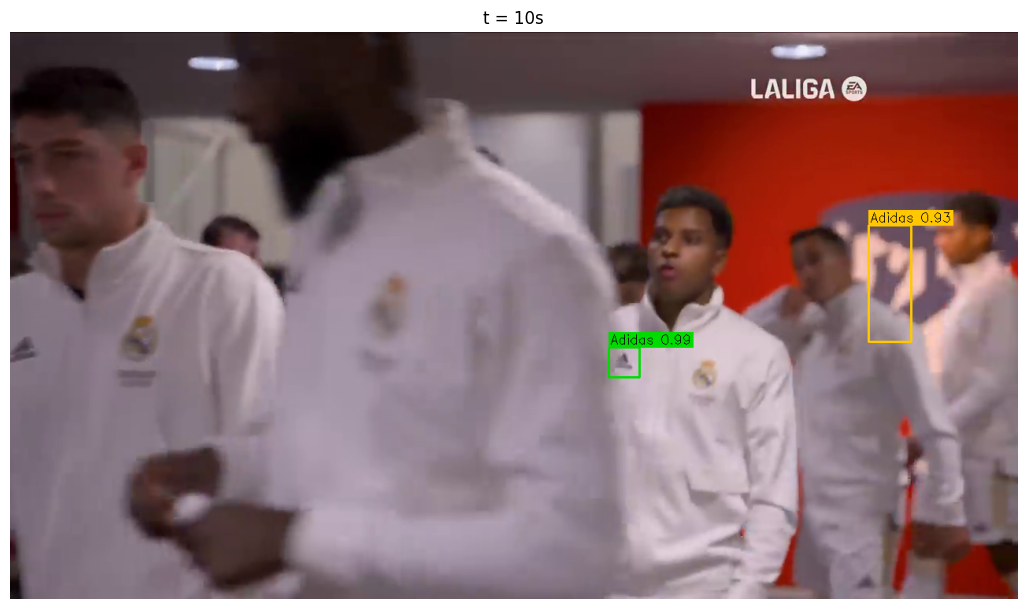


[t=30s] 用时 0.05s | 接受 0 个候选: []


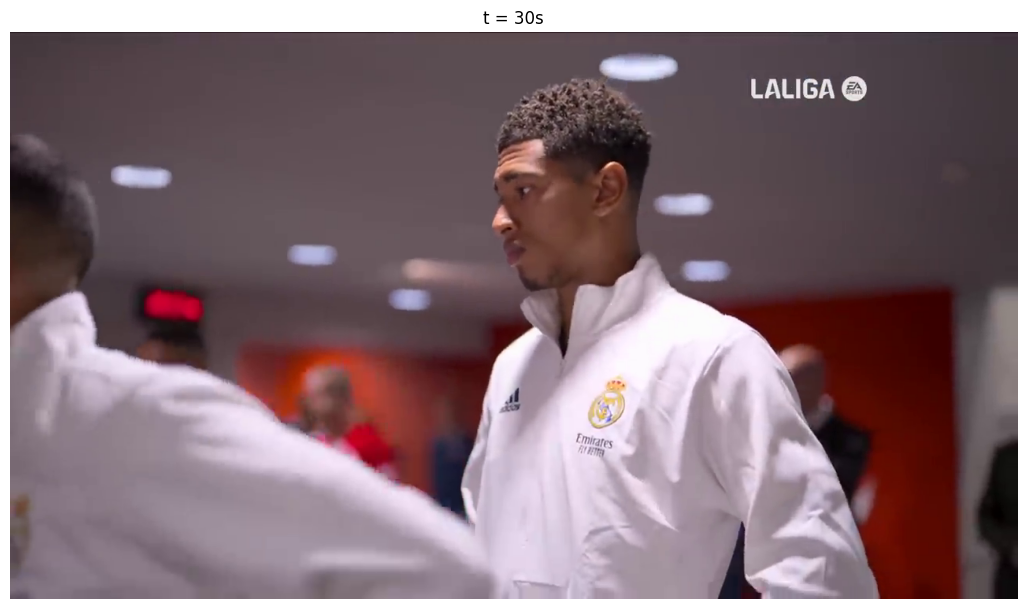


[t=60s] 用时 0.47s | 接受 6 个候选: [('Spotify', 0.67), ('Nike', 0.61), ('barclays', 0.9), ('Adidas', 0.64), ('barclays', 0.8), ('AKPET', 0.61)]


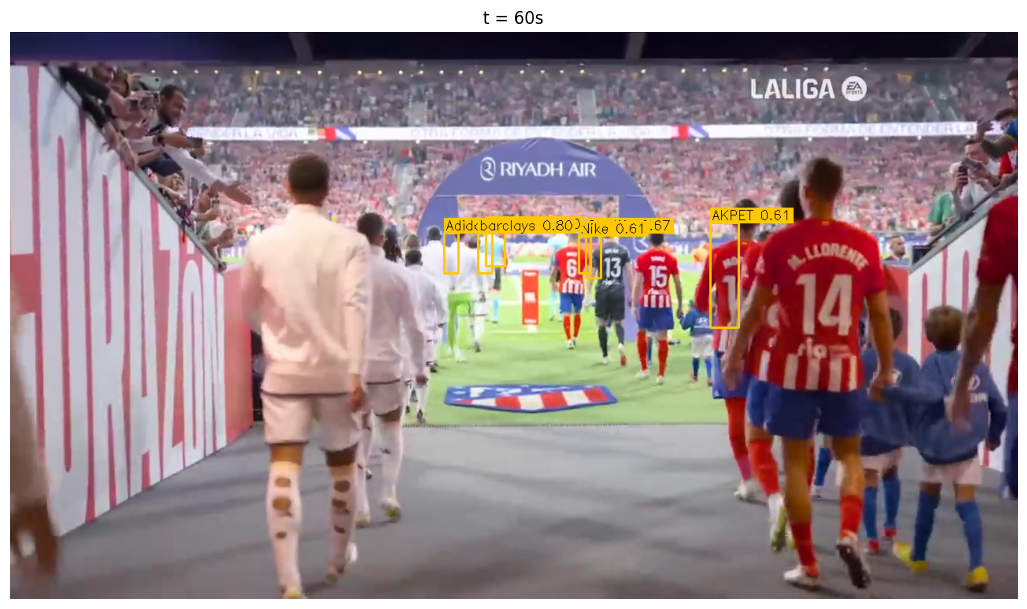

In [10]:
def draw_frame(frame_bgr, records):
    vis = frame_bgr.copy()
    for r in records:
        x1, y1, x2, y2 = r["box"]
        color = (0, 220, 0) if r["source"] == "yolo" else (0, 200, 255)
        cv2.rectangle(vis, (x1, y1), (x2, y2), color, 2)
        label = "%s %.2f%s" % (r["brand"], r["conf"],
                               "" if r["track_id"] is None else " #%s" % r["track_id"])
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
        cv2.rectangle(vis, (x1, max(0, y1 - th - 6)), (x1 + tw + 4, y1), color, -1)
        cv2.putText(vis, label, (x1 + 2, max(12, y1 - 4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 1)
    return vis


def grab_frame(video_path, second):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(second * fps))
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError("取帧失败: %s s" % second)
    return frame


PROBE_SECONDS = [10, 30, 60]

for sec in PROBE_SECONDS:
    try:
        frame = grab_frame(VIDEO_PATH, sec)
    except Exception as e:
        print("跳过", sec, e)
        continue
    if PROC_MAX_WIDTH and frame.shape[1] > PROC_MAX_WIDTH:
        s = PROC_MAX_WIDTH / frame.shape[1]
        frame = cv2.resize(frame, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    t0 = time.time()
    recs = analyze_frame(frame, track_ids=False)
    dt = time.time() - t0
    vis = draw_frame(frame, recs)
    print("\n[t=%.0fs] 用时 %.2fs | 接受 %d 个候选: %s"
          % (sec, dt, len(recs), [(r["brand"], round(r["conf"], 2)) for r in recs]))
    plt.figure(figsize=(13, 7.5))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("t = %ds" % sec)
    plt.show()

## 9. 整段视频：跟踪 + 时序投票

单帧结果会抖，所以每个 logo 用 ByteTrack 拿到 `track_id`，把同一 track 的多帧品牌概率投票聚合：

- 单帧误判被多帧投票压掉；
- 顺便得到 `start / end / duration`，直接就是曝光时长。

In [11]:
def run_video(video_path, max_seconds=MAX_SECONDS, frame_stride=FRAME_STRIDE,
              proc_max_width=PROC_MAX_WIDTH, save_annotated=False,
              min_track_frames=MIN_TRACK_FRAMES, log_every=50):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise FileNotFoundError(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    limit = total if max_seconds is None else min(total, int(max_seconds * fps))

    tracks = defaultdict(lambda: {"votes": Counter(), "conf_sum": 0.0, "n": 0,
                                  "first": None, "last": None, "best_conf": -1.0,
                                  "best_crop": None, "box": None})
    writer = None
    vis_path = OUT_DIR / (Path(video_path).stem + "_annotated.mp4") if save_annotated else None

    idx, processed, t0 = 0, 0, time.time()
    persist = False
    while idx < limit:
        ok, frame = cap.read()
        if not ok:
            break
        i = idx
        idx += 1
        if frame_stride > 1 and (i % frame_stride):
            continue

        if proc_max_width and frame.shape[1] > proc_max_width:
            s = proc_max_width / frame.shape[1]
            frame = cv2.resize(frame, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)

        recs = analyze_frame(frame, track_ids=True, persist=persist)
        persist = True
        t = i / fps

        for k, r in enumerate(recs):
            tid = r["track_id"] if r["track_id"] is not None else "anon_%d_%d" % (i, k)
            tr = tracks[tid]
            tr["votes"][r["brand"]] += 1
            tr["conf_sum"] += float(r["conf"])
            tr["n"] += 1
            tr["first"] = t if tr["first"] is None else min(tr["first"], t)
            tr["last"] = t if tr["last"] is None else max(tr["last"], t)
            if r["conf"] > tr["best_conf"]:
                tr["best_conf"] = float(r["conf"])
                tr["best_crop"] = r["crop"]
                tr["box"] = r["box"]

        if save_annotated:
            if writer is None:
                hh, ww = frame.shape[:2]
                writer = cv2.VideoWriter(str(vis_path), cv2.VideoWriter_fourcc(*"mp4v"),
                                         fps, (ww, hh))
                print("标注视频 ->", vis_path)
            writer.write(draw_frame(frame, recs))

        processed += 1
        if processed % log_every == 0:
            el = time.time() - t0
            speed = processed / max(el, 1e-6)
            remain = (limit / max(frame_stride, 1) - processed) / max(speed, 1e-6)
            print("  帧 %6d/%d | %.1f fps | 已用 %.0fs | 预计剩余 %.0fs | track=%d"
                  % (i, limit, speed, el, remain, len(tracks)))

    cap.release()
    if writer is not None:
        writer.release()

    rows = []
    for tid, tr in tracks.items():
        n = sum(tr["votes"].values())
        if n < min_track_frames:
            continue
        brand, votes = tr["votes"].most_common(1)[0]
        rows.append({
            "track_id": tid, "brand": brand, "n_frames": n,
            "vote_ratio": votes / n,
            "mean_conf": tr["conf_sum"] / max(n, 1),
            "best_conf": tr["best_conf"],
            "start_s": round(tr["first"], 2),
            "end_s": round(tr["last"], 2),
            "duration_s": round(tr["last"] - tr["first"] + 1.0 / fps, 2),
            "box": tr["box"],
        })

    df = pd.DataFrame(rows)
    if len(df):
        df = df.sort_values("duration_s", ascending=False).reset_index(drop=True)

    print("\n处理帧数=%d | 有效 track=%d | 总耗时 %.1fs"
          % (processed, len(df), time.time() - t0))

    if SAVE_BRAND_CROPS and len(df):
        crop_dir = OUT_DIR / "brand_crops"
        crop_dir.mkdir(parents=True, exist_ok=True)
        seen = Counter()
        for tid, tr in tracks.items():
            if tr["best_crop"] is None:
                continue
            brand, votes = tr["votes"].most_common(1)[0]
            if seen[brand] >= CROP_SAVE_LIMIT:
                continue
            safe = re.sub(r"[^A-Za-z0-9._-]+", "_", str(brand))[:40]
            cv2.imwrite(str(crop_dir / ("%s_%s_%d.jpg" % (safe, str(tid)[:12], seen[brand]))),
                        cv2.cvtColor(tr["best_crop"], cv2.COLOR_RGB2BGR))
            seen[brand] += 1
        print("代表图 ->", crop_dir)

    return df

## 10. 跑起来

默认只处理前 `MAX_SECONDS=120` 秒。想跑全片把 `MAX_SECONDS=None`（会很慢，建议先估速）。

In [12]:
exposure_df = run_video(VIDEO_PATH,
                        max_seconds=MAX_SECONDS,
                        frame_stride=FRAME_STRIDE,
                        save_annotated=SAVE_ANNOTATED_VIDEO)

CSV_PATH = OUT_DIR / "exposure_tracks.csv"
if len(exposure_df):
    exposure_df.to_csv(CSV_PATH, index=False)
    print("逐 track 明细 ->", CSV_PATH)
    display(exposure_df.head(30))
else:
    print("没有检测到任何跨帧稳定的品牌")

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 189ms
Prepared 1 package in 49ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

  帧     49/3000 | 3.9 fps | 已用 13s | 预计剩余 766s | track=98
  帧     99/3000 | 3.3 fps | 已用 30s | 预计剩余 866s | track=219
  帧    149/3000 | 3.3 fps | 已用 45s | 预计剩余 864s | track=326
  帧    199/3000 | 3.3 fps | 已用 61s | 预计剩余 849s | track=438
  帧    249/3000 | 3.7 fps | 已用 67s | 预计剩余 733s | track=527
  帧    299/3000 | 4.2 fps | 已用 72s | 预计剩余 646s | track=607
  帧    349/3000 | 4.5 fps | 已用 78s | 预计剩余 588s | track=705
  帧    399/3000 | 4.8 fps | 已用 83s | 预计剩余 537s | track=773
  帧    449/3000 | 5.1 fps | 已用 89s | 预计剩余 504s | track=853
  帧    499/3000 | 5.4 fps | 已用 93s | 预计剩余 464s | track=884
  帧    549/3000 | 5.7 fps | 已用 96s | 预计剩余 429s | track

,track_id,brand,n_frames,vote_ratio,mean_conf,best_conf,start_s,end_s,duration_s,box
0,531,barclays,61,0.704918,0.756832,0.925434,61.36,68.76,7.44,"(544, 226, 589, 301)"
1,189,Adidas,130,0.976923,0.967846,0.997229,15.08,21.36,6.32,"(663, 375, 710, 416)"
2,36,Nike,137,0.978102,0.956637,0.999278,2.32,8.20,5.92,"(632, 618, 658, 640)"
3,765,Nike,110,1.000000,0.997422,0.999001,109.84,114.28,4.48,"(412, 590, 503, 639)"
4,312,Nike,71,0.661972,0.993637,0.998984,32.92,37.32,4.44,"(410, 367, 436, 385)"
5,12,Nike,92,1.000000,0.981727,0.999472,0.96,5.16,4.24,"(595, 647, 641, 672)"
6,624,MuzzBuzz,4,0.250000,0.664611,0.791274,79.88,83.68,3.84,"(67, 522, 235, 590)"
7,31,Nike,87,1.000000,0.970695,0.999337,2.08,5.76,3.72,"(812, 414, 839, 435)"
8,320,Nike,58,0.948276,0.996580,0.999170,33.24,35.72,2.52,"(169, 570, 208, 592)"
9,259,Nike,61,0.934426,0.995472,0.999230,31.36,33.80,2.48,"(83, 607, 138, 637)"


## 11. 结果汇总

- **品牌级曝光时长**：把同一品牌的 track 时长加起来
- 注意：多个球员同时穿同一赞助商时会有重叠，这里的"总曝光"是**累加值**（按球员计费的口径），
  如果要"品牌出现在画面里的墙钟时长"，需要对时间区间做并集。

品牌级汇总 -> /content/inference_out/exposure_by_brand.csv


,brand,tracks,total_duration_s,mean_conf,max_single_s,share_%
0,Nike,32,49.76,0.956123,5.92,55.0
1,Adidas,16,18.20,0.965269,6.32,20.1
2,barclays,2,7.56,0.773403,7.44,8.4
3,Spotify,5,5.48,0.748490,1.68,6.1
4,MuzzBuzz,1,3.84,0.664611,3.84,4.2
5,Emirates,3,3.08,0.942982,1.92,3.4
6,3t cycling,1,1.96,0.687840,1.96,2.2
7,BlackandRed,1,0.48,0.643743,0.48,0.5
8,AntonioGimenez,1,0.12,0.880451,0.12,0.1


墙钟口径：画面里出现赞助 logo 的总时长 = 53.2 秒（45.7%）


/tmp/ipykernel_1591/4135146826.py:36: UserWarning: Glyph 26333 (\N{CJK UNIFIED IDEOGRAPH-66DD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:36: UserWarning: Glyph 20809 (\N{CJK UNIFIED IDEOGRAPH-5149}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:36: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:36: UserWarning: Glyph 38271 (\N{CJK UNIFIED IDEOGRAPH-957F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:36: UserWarning: Glyph 31186 (\N{CJK UNIFIED IDEOGRAPH-79D2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:36: UserWarning: Glyph 21697 (\N{CJK UNIFIED IDEOGRAPH-54C1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:36: UserWarning: Glyph 29260 (\N{CJK UNIFIED IDEOGRAPH-724C}

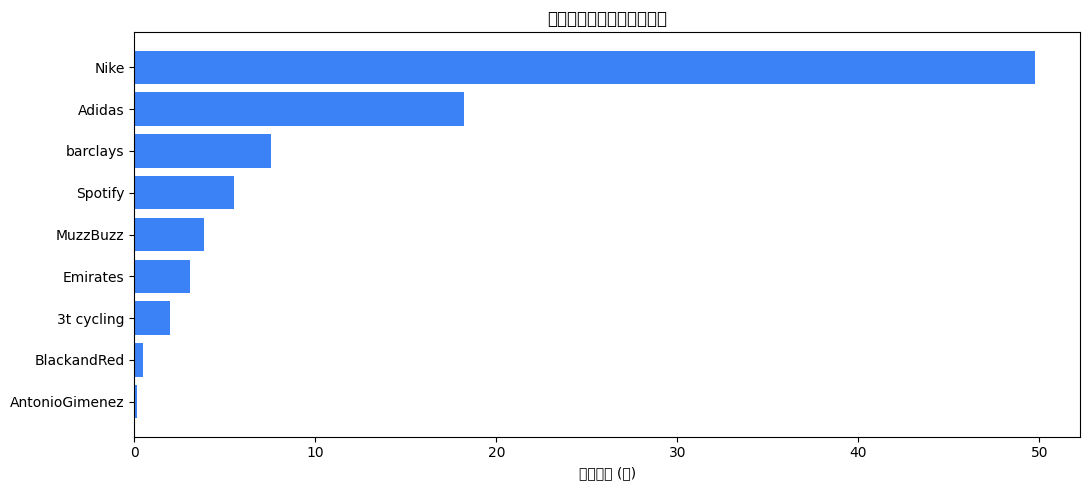

/tmp/ipykernel_1591/4135146826.py:48: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:48: UserWarning: Glyph 38388 (\N{CJK UNIFIED IDEOGRAPH-95F4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:48: UserWarning: Glyph 31186 (\N{CJK UNIFIED IDEOGRAPH-79D2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:48: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:48: UserWarning: Glyph 20010 (\N{CJK UNIFIED IDEOGRAPH-4E2A}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:48: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1591/4135146826.py:48: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}

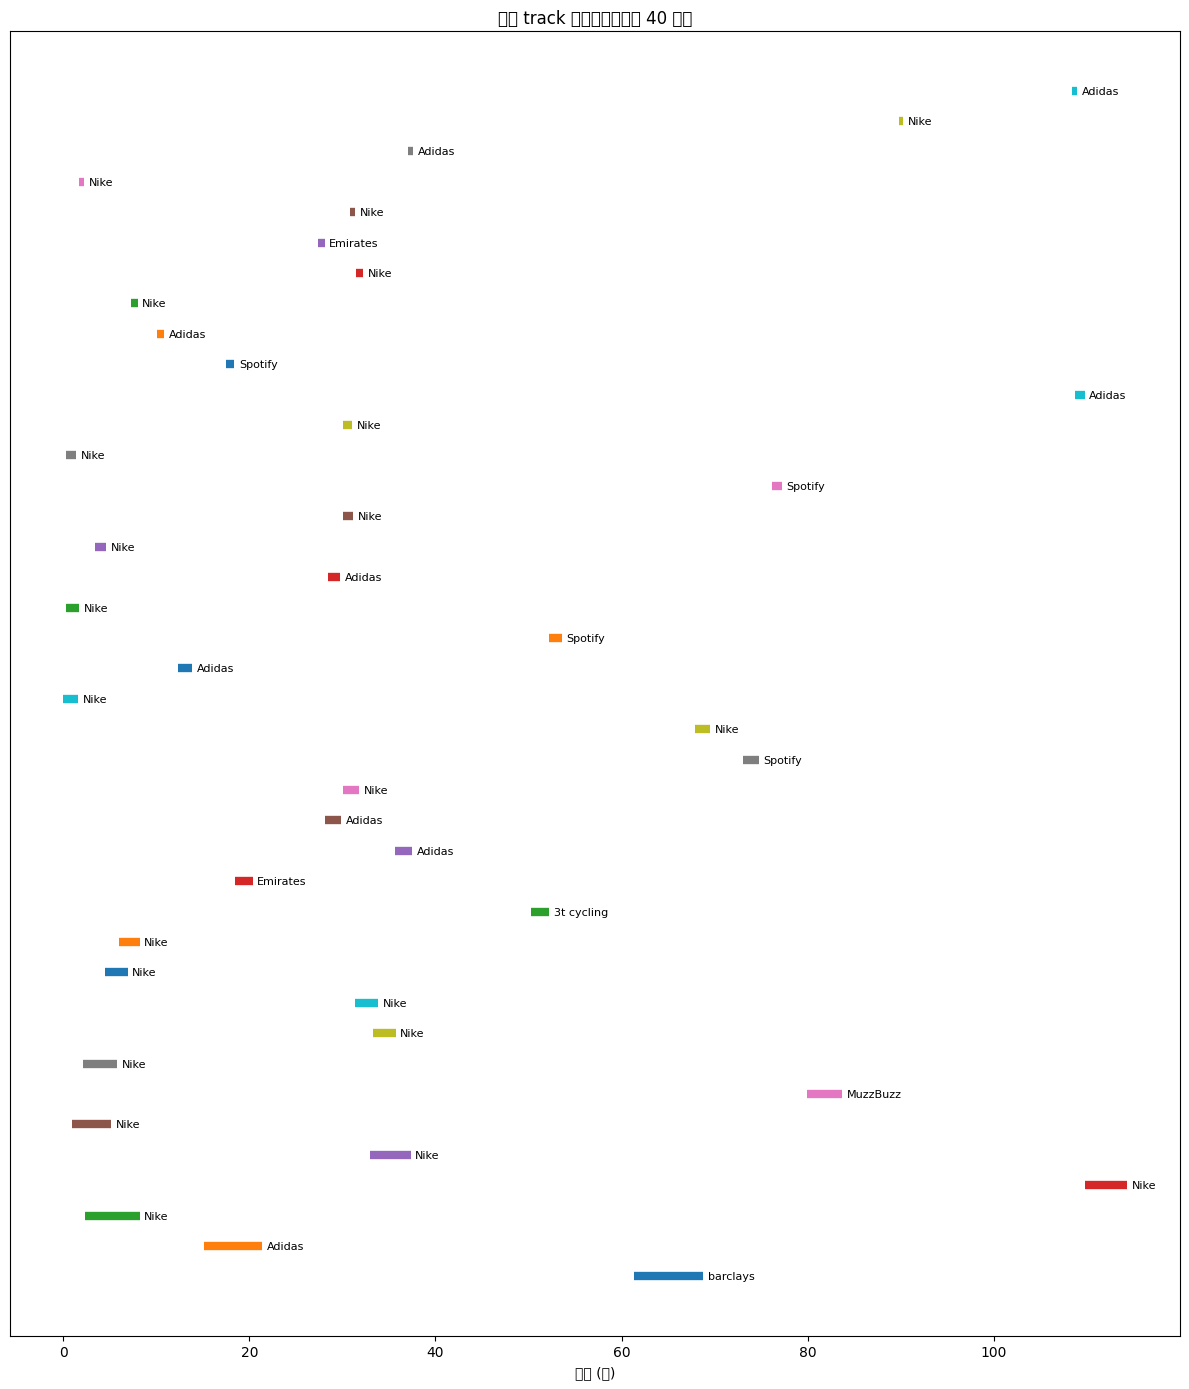

In [13]:
if len(exposure_df):
    # 品牌级汇总
    agg = (exposure_df.groupby("brand")
           .agg(tracks=("track_id", "count"),
                total_duration_s=("duration_s", "sum"),
                mean_conf=("mean_conf", "mean"),
                max_single_s=("duration_s", "max"))
           .sort_values("total_duration_s", ascending=False)
           .reset_index())
    agg["share_%"] = (100 * agg["total_duration_s"] / agg["total_duration_s"].sum()).round(1)
    CSV_AGG = OUT_DIR / "exposure_by_brand.csv"
    agg.to_csv(CSV_AGG, index=False)
    print("品牌级汇总 ->", CSV_AGG)
    display(agg)

    # 墙钟口径：把区间并集
    spans = sorted(zip(exposure_df["start_s"], exposure_df["end_s"]))
    merged, cur = [], None
    for s, e in spans:
        if cur is None:
            cur = [s, e]
        elif s <= cur[1]:
            cur[1] = max(cur[1], e)
        else:
            merged.append(tuple(cur)); cur = [s, e]
    if cur:
        merged.append(tuple(cur))
    wall = sum(e - s for s, e in merged)
    print("墙钟口径：画面里出现赞助 logo 的总时长 = %.1f 秒（%.1f%%）"
          % (wall, 100 * wall / max(merged[-1][1] - merged[0][0], 1e-6) if merged else 0))

    plt.figure(figsize=(11, 5))
    plt.barh(agg["brand"][::-1], agg["total_duration_s"][::-1], color="#3b82f6")
    plt.xlabel("曝光时长 (秒)")
    plt.title("品牌曝光时长（累加口径）")
    plt.tight_layout()
    plt.show()

    # 时间轴
    plt.figure(figsize=(12, max(2.5, 0.35 * len(exposure_df.head(40)))))
    for k, row in exposure_df.head(40).iterrows():
        plt.plot([row["start_s"], row["end_s"]], [k, k], lw=6,
                 solid_capstyle="butt")
        plt.text(row["end_s"] + 0.5, k, row["brand"], va="center", fontsize=8)
    plt.xlabel("时间 (秒)")
    plt.yticks([])
    plt.title("每个 track 的出现区间（前 40 条）")
    plt.tight_layout()
    plt.show()
else:
    print("无结果可汇总")

## 12. 调参与已知限制

### 常见调参

| 现象 | 调什么 |
|---|---|
| 漏检多 | 降 `LOGO_CONF`（0.10 → 0.05）、开 `USE_GEOMETRIC_PRIORS`、提高 `IMGSZ` |
| 误报多 | 升 `DOCTOR_MIN_CONF` / `DOCTOR_MIN_MARGIN`、升 `PRIOR_MIN_CONF`、`MAX_ACCEPTED_PER_PLAYER=1` |
| track 碎 | 降 `MIN_TRACK_FRAMES`、升 `LOGO_IOU`（0.5 → 0.6） |
| 太慢 | 降 `IMGSZ`、`FRAME_STRIDE=2`、`PROC_MAX_WIDTH=960` |

### 已知限制

1. **没有 open-set 兜底**：Doctor 是闭集，遇到训练里没有的品牌会硬给一个最近类。
   本 notebook 只用阈值 + `other` 类拒绝；要真正识别新品牌，需要接 CLIP 或 brand gallery（v3 里有）。
2. **track 之间不合并**：同一件球衣换 track ID 会被切成两段，曝光时长偏短。
3. **曝光时长没按可见面积加权**：被遮挡的 logo 仍按满时长计。
4. **不同球员同品牌会重复计时**（累加口径），墙钟口径见上一格。